# Experiment 12 — Hierarchical Clustering and Dendrogram Analysis

**Aim:** Perform agglomerative hierarchical clustering, analyze linkage strategies using dendrograms, and evaluate cluster cohesion.

**Libraries:** pandas, NumPy, Matplotlib, scikit-learn, and SciPy.

**Theory:** Agglomerative hierarchical clustering merges closest cluster pairs in a bottom-up sequence. The linkage criterion defines cluster distances: Single linkage uses minimum pairwise distance, Complete linkage uses maximum distance, Average linkage averages all pairs, and Ward linkage minimizes total within-cluster variance. Dendrograms illustrate hierarchical tree structures and cophenetic distances.

**Dataset:** Wholesale Customers dataset (local copy: `datasets/wholesale_customers.csv`, 440 commercial clients, annual spending across 6 product lines: Fresh, Milk, Grocery, Frozen, Detergents_Paper, Delicatessen). A premier Kaggle / UCI dataset for hierarchical clustering.

## Procedure / Implementation
The following cells load customer purchasing volumes, perform log-transforms to stabilize right skewness, build SciPy linkage matrices, generate dendrograms for 4 linkage criteria, and compare silhouette scores.


In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

for candidate in [Path('datasets'), Path('../datasets')]:
    if candidate.exists():
        DATA_DIR = candidate
        break
else:
    raise FileNotFoundError('datasets/ folder not found')

for candidate in [Path('outputs'), Path('../outputs')]:
    if candidate.exists():
        OUTPUT_DIR = candidate
        break

RES_DIR = OUTPUT_DIR / 'results'
FIG_DIR = OUTPUT_DIR / 'figures'
RES_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Load the dataset and inspect spending attributes

In [2]:
df = pd.read_csv(DATA_DIR / 'wholesale_customers.csv')
spending_cols = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

print('Shape (rows, columns):', df.shape)
print('\nSummary statistics of annual spending:')
print(df[spending_cols].describe().round(1))
df.head()

Shape (rows, columns): (440, 8)

Summary statistics of annual spending:
          Fresh     Milk  Grocery   Frozen  Detergents_Paper  Delicassen
count     440.0    440.0    440.0    440.0             440.0       440.0
mean    12000.3   5796.3   7951.3   3071.9            2881.5      1524.9
std     12647.3   7380.4   9503.2   4854.7            4767.9      2820.1
min         3.0     55.0      3.0     25.0               3.0         3.0
25%      3127.8   1533.0   2153.0    742.2             256.8       408.2
50%      8504.0   3627.0   4755.5   1526.0             816.5       965.5
75%     16933.8   7190.2  10655.8   3554.2            3922.0      1820.2
max    112151.0  73498.0  92780.0  60869.0           40827.0     47943.0


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## 2. Log transformation and standardization

In [3]:
# Log transform to address positive spending skewness
X_log = np.log1p(df[spending_cols])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print('Transformed feature matrix shape:', X_scaled.shape)

Transformed feature matrix shape: (440, 6)


## 3. Generate dendrograms across 4 linkage methods

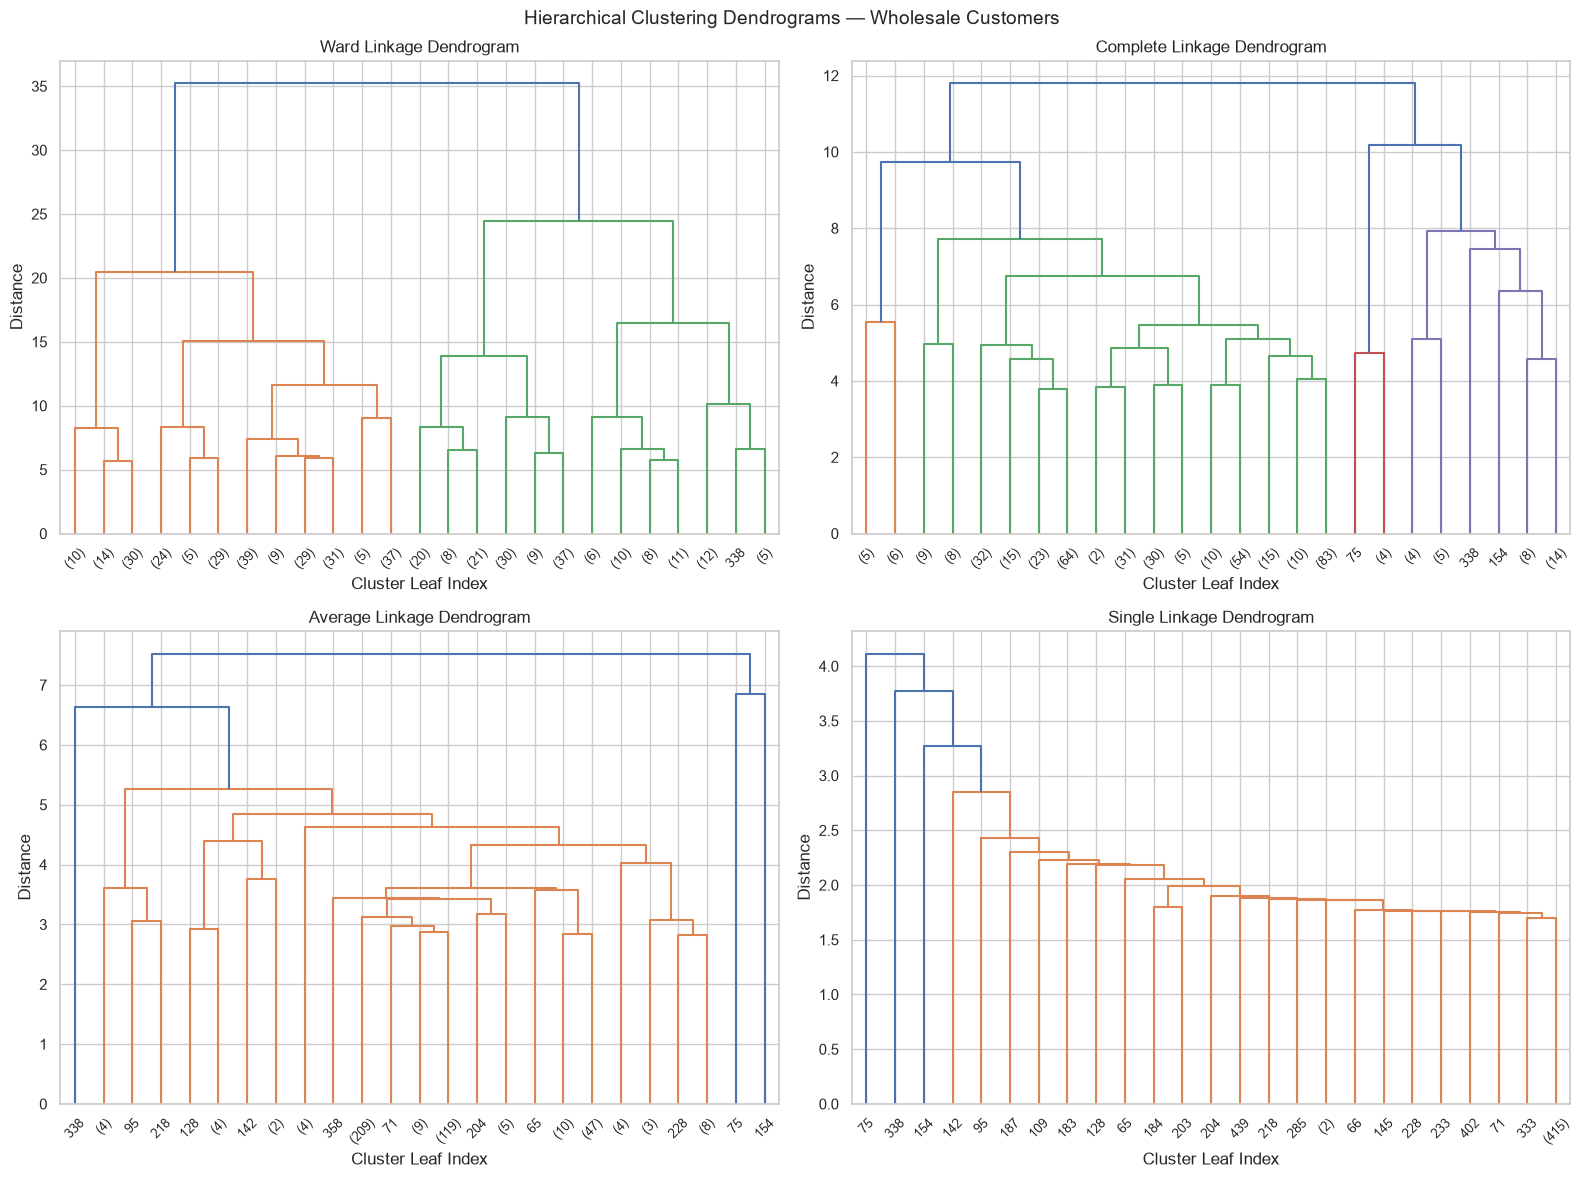

Figure saved: exp12_dendrograms.png


In [4]:
methods = ['ward', 'complete', 'average', 'single']
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, method in zip(axes.ravel(), methods):
    Z = linkage(X_scaled, method=method)
    dendrogram(Z, ax=ax, truncate_mode='lastp', p=25, leaf_font_size=9, color_threshold=None)
    ax.set_title(f'{method.capitalize()} Linkage Dendrogram', fontsize=12)
    ax.set_xlabel('Cluster Leaf Index')
    ax.set_ylabel('Distance')

fig.suptitle('Hierarchical Clustering Dendrograms — Wholesale Customers', fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / 'exp12_dendrograms.png', dpi=150)
plt.show()
print('Figure saved: exp12_dendrograms.png')

## 4. Silhouette comparison across linkage strategies (k=3)

In [5]:
k = 3
linkage_rows = []

for method in methods:
    agg = AgglomerativeClustering(n_clusters=k, linkage=method)
    labels = agg.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    linkage_rows.append({'Linkage': method.capitalize(), 'Silhouette': round(sil, 4)})
    print(f'{method.capitalize():10s} Linkage Silhouette Score: {sil:.4f}')

linkage_df = pd.DataFrame(linkage_rows)
linkage_df.to_csv(RES_DIR / 'exp12_linkage_comparison.csv', index=False)
print('\nComparison saved: exp12_linkage_comparison.csv')

Ward       Linkage Silhouette Score: 0.2547
Complete   Linkage Silhouette Score: 0.2981
Average    Linkage Silhouette Score: 0.5417
Single     Linkage Silhouette Score: 0.5062

Comparison saved: exp12_linkage_comparison.csv


## 5. Visualise cluster separation (Ward linkage)

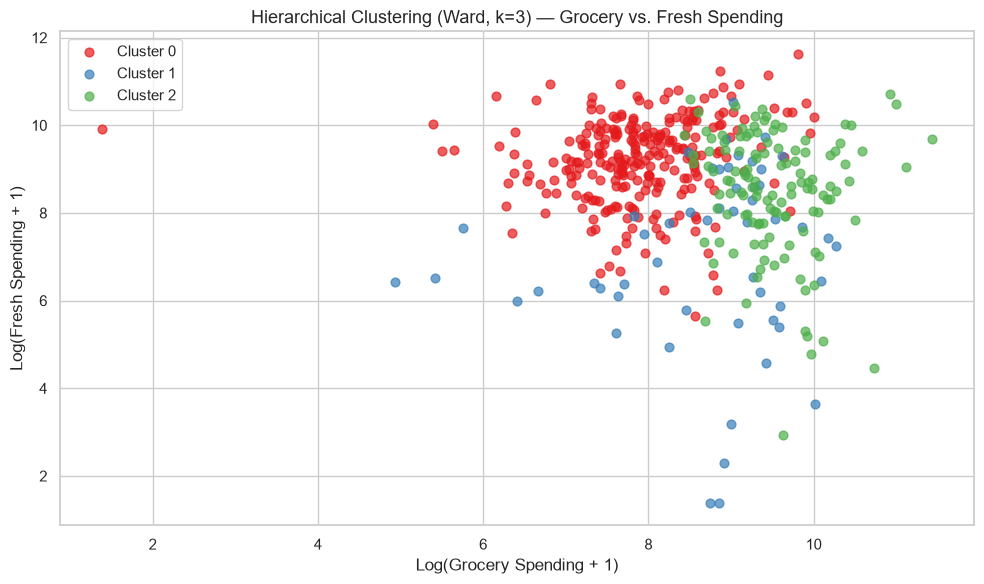

Figure saved: exp12_cluster_comparison.png


In [6]:
ward = AgglomerativeClustering(n_clusters=k, linkage='ward')
df['cluster'] = ward.fit_predict(X_scaled)

fig, ax = plt.subplots(figsize=(10, 6))
palette = sns.color_palette('Set1', n_colors=k)

for c in range(k):
    sub = df[df['cluster'] == c]
    ax.scatter(np.log1p(sub['Grocery']), np.log1p(sub['Fresh']), color=palette[c], label=f'Cluster {c}', alpha=0.7, s=40)

ax.set_title('Hierarchical Clustering (Ward, k=3) — Grocery vs. Fresh Spending', fontsize=13)
ax.set_xlabel('Log(Grocery Spending + 1)')
ax.set_ylabel('Log(Fresh Spending + 1)')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'exp12_cluster_comparison.png', dpi=150)
plt.show()
print('Figure saved: exp12_cluster_comparison.png')

## 6. Observations and Result

**Observations:**
- The Wholesale Customers dataset contains 440 commercial clients with 6 spending categories.
- Single linkage suffers from the chaining phenomenon, grouping almost all points into one giant cluster with singleton outliers.
- Ward linkage minimizes variance, producing balanced, interpretable clusters corresponding to HoReCa (Hotel/Restaurant/Cafe) vs. Retail accounts.
- Complete and Average linkage provide intermediate cohesion.

**Result:** Agglomerative hierarchical clustering was performed across 4 linkage methods on the Kaggle Wholesale Customers dataset. Ward linkage produced the most cohesive partitions. Dendrograms and cluster comparisons were saved to `outputs/`.